#### **IMPORTS**

In [ ]:
import spikeinterface as si
import numpy as np
import spikeinterface as si
from pathlib import Path
import matplotlib.pyplot as plt
import os

/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
rec_dir = r'/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed'
rec = si.load(rec_dir)
print(rec)

base_dir  = Path(rec_dir) / "thresholding_peaks_3.3"
peaks_path  = base_dir / "peaks_combined2_sorted.npy"
motion_path = base_dir / "motion_estimates" / "chunks_n12" / "motion_dredge_0000min_0070min"

peaks  = np.load(peaks_path)
motion = si.Motion.load(motion_path)
print(f"Peaks: {len(peaks):,}  |  fields: {peaks.dtype.names}")

estimated_peak_locations = np.load('/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3/localized_peaks_mt_raw.npy')
print(f"Estimated peak locations shape: {estimated_peak_locations.shape}")
depths = estimated_peak_locations['y']

plot_start_time = 500
plot_end_time = 500 + 5*60

BinaryFolderRecording: 368 channels - 30.0kHz - 1 segments - 1,082,222,502 samples 
                       36,074.08s (10.02 hours) - float16 dtype - 741.81 GiB
Peaks: 126,258,007  |  fields: ('sample_index', 'channel_index', 'amplitude', 'segment_index', 'z')


Estimated peak locations shape: (126258007,)


In [ ]:
time_offset = rec.get_times()[0]
print(time_offset)
print(rec.get_times()[-1])

13853.9454
49928.02876666667


#### **FUNCTIONS**

In [ ]:
def plot_drift_scatter(peaks, depths, sampling_frequency, t_min=None, t_max=None, save_name=None):
    times = peaks['sample_index'] / sampling_frequency
    mask = np.ones(len(times), dtype=bool)
    if t_min is not None:
        mask &= times >= t_min
    if t_max is not None:
        mask &= times <= t_max
    
    times = times[mask]
    depths = depths[mask]
    
    plt.figure(figsize=(15, 15))
    plt.scatter(times, depths, s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title('Estimated Peak Depths Over Time')
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


In [ ]:
def plot_motion_overlay(peaks, depths, motion_list, labels, colors, sampling_frequency,
                        start_time=None, end_time=None, time_offset=0, save_name=None):
    """Scatter of peak depths with drift lines overlaid.
    Each item in motion_list can be an si.Motion object or a dict with
    keys 'time_bins', 'depth_bins', 'dshift'.
    Drift lines cycle through distinct colours (each neighbouring window gets
    a different colour; colours repeat after one cycle).
    Multiple motion sources in motion_list are distinguished by linestyle.
    """
    DEPTH_COLORS = [
        'red', 'royalblue', 'darkgreen', 'darkorange', 'deeppink', 'saddlebrown', 'teal'
    ]

    plt.figure(figsize=(16, 16))

    peak_times = peaks['sample_index'] / sampling_frequency

    if start_time is None:
        start_time = peak_times.min()
    if end_time is None:
        end_time = peak_times.max()

    time_mask = (peak_times >= start_time) & (peak_times <= end_time)
    plt.scatter(peak_times[time_mask], depths[time_mask],
                s=1, color='k', alpha=0.01, label='Individual Spikes')

    linestyles = ['-', '--', ':', '-.']

    for m_idx, motion_src in enumerate(motion_list):
        label_base = labels[m_idx]
        ls = linestyles[m_idx % len(linestyles)]

        if isinstance(motion_src, dict):
            t_bins  = motion_src['time_bins']
            d_bins  = motion_src['depth_bins']
            dshift_ = motion_src['dshift']
        else:  # si.Motion
            t_bins  = motion_src.temporal_bins_s[0] - time_offset
            d_bins  = motion_src.spatial_bins_um
            dshift_ = motion_src.displacement[0]

        t_mask = (t_bins >= start_time) & (t_bins <= end_time)
        for i, start_depth in enumerate(d_bins):
            color = DEPTH_COLORS[i % len(DEPTH_COLORS)]  # cycle: each neighbour gets a different colour
            label = label_base if i == 0 else ""
            drift_line = start_depth + dshift_[:, i]
            plt.plot(t_bins[t_mask], drift_line[t_mask],
                     color=color, linewidth=1.2, alpha=0.8, label=label, linestyle=ls)

    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title(f'Motion Estimation  [{start_time:.1f}s - {end_time:.1f}s]')
    plt.xlim(start_time, end_time)
    plt.legend(loc='upper right', markerscale=10)
    plt.grid(True, alpha=0.2)
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


In [ ]:
def get_corrected_depths(peaks, depths, motion_src, sampling_frequency, time_offset=0):
    """Subtract motion shift from depths.
    motion_src can be an si.Motion object or a dict with keys 'time_bins', 'depth_bins', 'dshift'.
    """
    peak_times = peaks['sample_index'] / sampling_frequency
    if isinstance(motion_src, dict):
        t_bins  = motion_src['time_bins']
        d_bins  = motion_src['depth_bins']
        dshift_ = motion_src['dshift']
        # searchsorted: no large broadcast matrix, O(n log m)
        t_idx = np.clip(np.searchsorted(t_bins, peak_times) - 1, 0, len(t_bins) - 1)
        d_idx = np.clip(np.searchsorted(d_bins, depths)     - 1, 0, len(d_bins) - 1)
        shifts = dshift_[t_idx, d_idx]
    else:  # si.Motion
        shifts = motion_src.get_displacement_at_time_and_depth(
            peak_times + time_offset, depths
        )
    return depths - shifts

In [ ]:
def get_channel_corrected_binned(peaks, channel_depths, motion_src, sampling_frequency,
                                  time_offset=0, bin_duration=10.0, smooth_sigma=0.0):
    """Non-rigid, time-binned channel correction.

    Non-rigid: each channel gets its own depth-dependent shift per time bin,
    matching DREDge's spatial_bins_um. Drift is evaluated at every channel's
    actual depth rather than at a single median depth.

    Parameters
    ----------
    bin_duration : float
        Width of time bins in seconds (default 10 s).
    smooth_sigma : float
        Sigma (in bins) for optional Gaussian smoothing of the drift matrix
        over the time axis before rounding. 0 = no smoothing (default).

    Returns
    -------
    corrected_channel : int array (n_peaks,)  -- corrected channel index
    bin_shifts_ref    : int array (n_bins,)   -- integer shift per bin at median depth (diagnostics)
    bin_centers       : float array (n_bins,) -- centre time of each bin
    """
    from scipy.ndimage import gaussian_filter1d

    peak_times = peaks['sample_index'] / sampling_frequency
    n_chan = len(channel_depths)

    sort_idx        = np.argsort(channel_depths)
    sorted_depths   = channel_depths[sort_idx]
    channel_spacing = float(np.median(np.diff(sorted_depths)))

    bin_edges   = np.arange(peak_times.min(), peak_times.max() + bin_duration, bin_duration)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    n_bins = len(bin_centers)

    # Build drift matrix: shape (n_chan, n_bins)
    # drift_matrix[ch, t] = displacement (um) at channel ch's depth at time bin t
    if isinstance(motion_src, dict):
        t_b     = motion_src['time_bins']
        d_b     = motion_src['depth_bins']
        dshift_ = motion_src['dshift']
        t_idx = np.clip(np.searchsorted(t_b, bin_centers)    - 1, 0, len(t_b) - 1)
        d_idx = np.clip(np.searchsorted(d_b, channel_depths) - 1, 0, len(d_b) - 1)
        drift_matrix = dshift_[np.ix_(t_idx, d_idx)].T   # (n_chan, n_bins)
    else:  # si.Motion -- vectorised over all (channel, bin) pairs
        ch_rep = np.repeat(channel_depths, n_bins)          # n_chan * n_bins
        t_rep  = np.tile(bin_centers + time_offset, n_chan)
        drift_matrix = motion_src.get_displacement_at_time_and_depth(
            t_rep, ch_rep
        ).reshape(n_chan, n_bins)

    if smooth_sigma > 0:
        drift_matrix = gaussian_filter1d(drift_matrix, sigma=smooth_sigma, axis=1)

    # Round drift to nearest integer number of channels  ->  (n_chan, n_bins)
    shifts_matrix = np.round(drift_matrix / channel_spacing).astype(int)

    # Each spike: look up its channel's shift at its time bin
    spike_bin       = np.clip(np.digitize(peak_times, bin_edges) - 1, 0, n_bins - 1)
    ch_idx          = peaks['channel_index']
    shift_per_spike = shifts_matrix[ch_idx, spike_bin]
    corrected_ch    = np.clip(ch_idx - shift_per_spike, 0, n_chan - 1)

    # Return median-channel bin shifts for diagnostics
    median_ch_idx  = np.argmin(np.abs(channel_depths - np.median(channel_depths)))
    bin_shifts_ref = shifts_matrix[median_ch_idx, :]

    return corrected_ch, bin_shifts_ref, bin_centers


def plot_channel_scatter(peaks, channel_idx, sampling_frequency, t_min=None, t_max=None,
                         save_name=None, title='Channel Index Over Time'):
    """Scatter plot of channel index (integer) vs time."""
    times = peaks['sample_index'] / sampling_frequency
    mask  = np.ones(len(times), dtype=bool)
    if t_min is not None:
        mask &= times >= t_min
    if t_max is not None:
        mask &= times <= t_max

    plt.figure(figsize=(15, 15))
    plt.scatter(times[mask], channel_idx[mask], s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Channel index')
    plt.title(title)
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


#### **LOCATIONS**

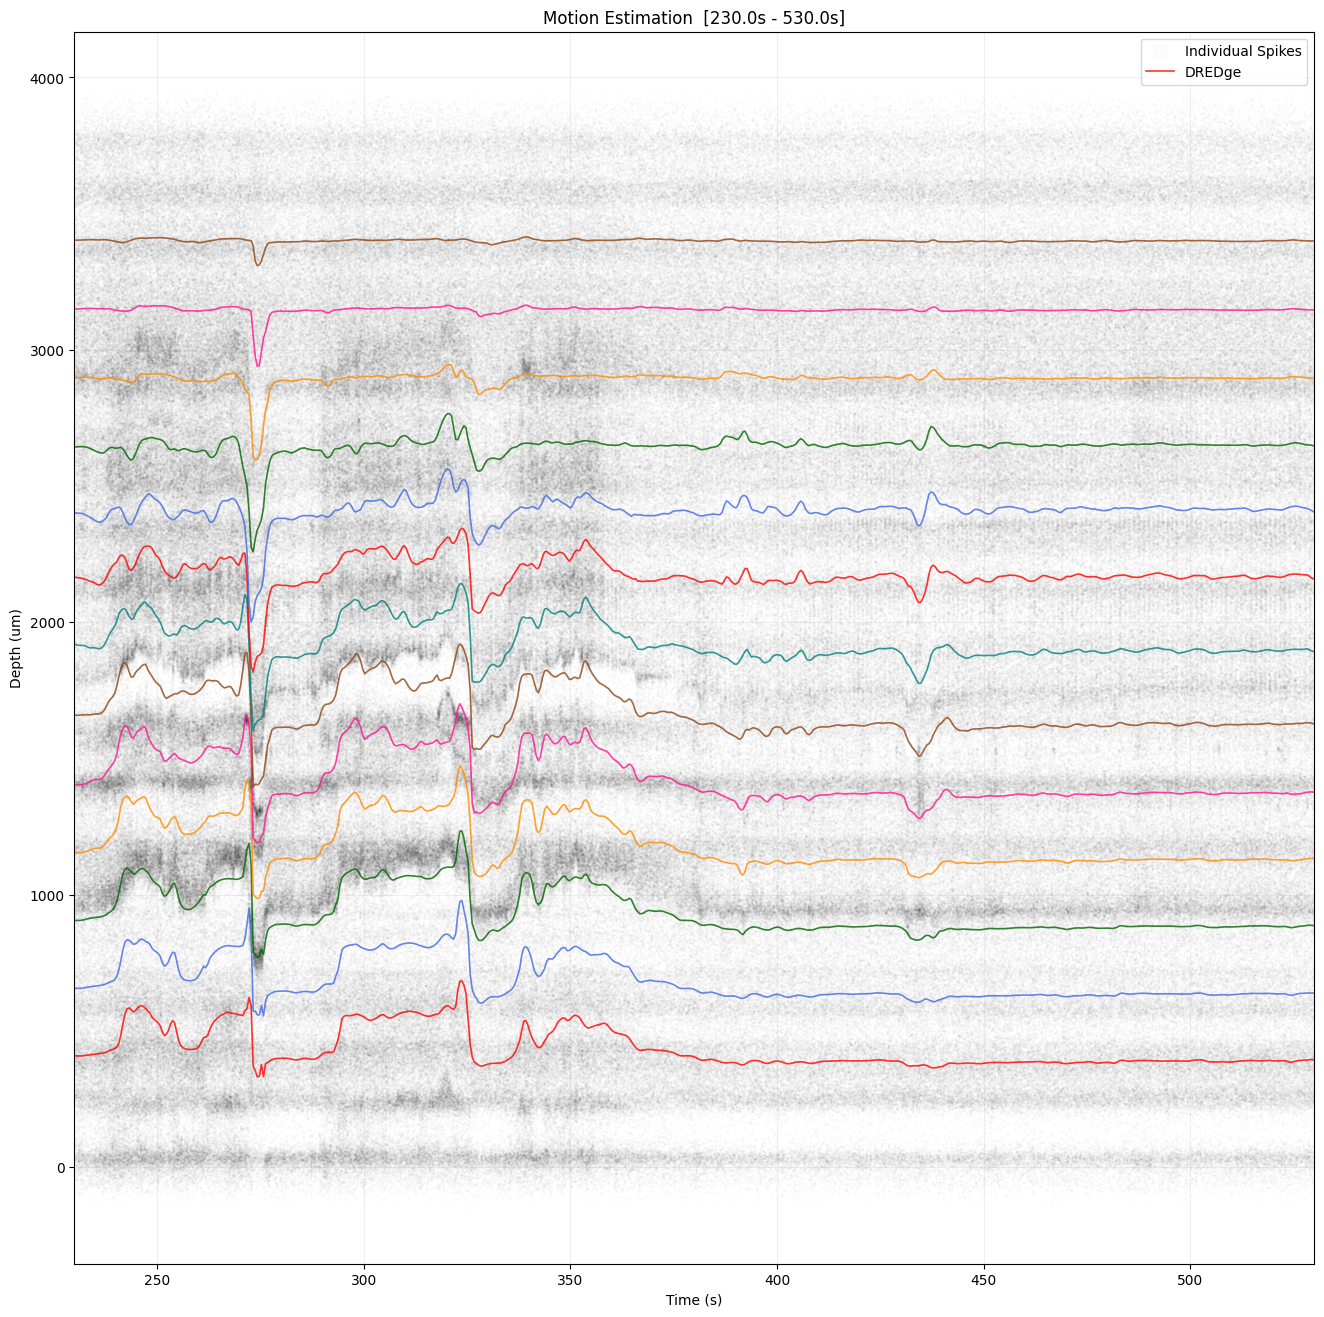

In [ ]:
plot_motion_overlay(
    peaks,
    depths,
    motion_list=[motion],
    labels=['DREDge'],
    colors=['red'],
    sampling_frequency=rec.sampling_frequency,
    time_offset=time_offset,
    start_time=plot_start_time,
    end_time=plot_end_time,
    save_name=motion_path / f'motion_overlay_dredge_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png'
)


In [ ]:
corrected_depths = get_corrected_depths(
    peaks,
    depths,
    motion,
    rec.sampling_frequency,
    time_offset=time_offset
)

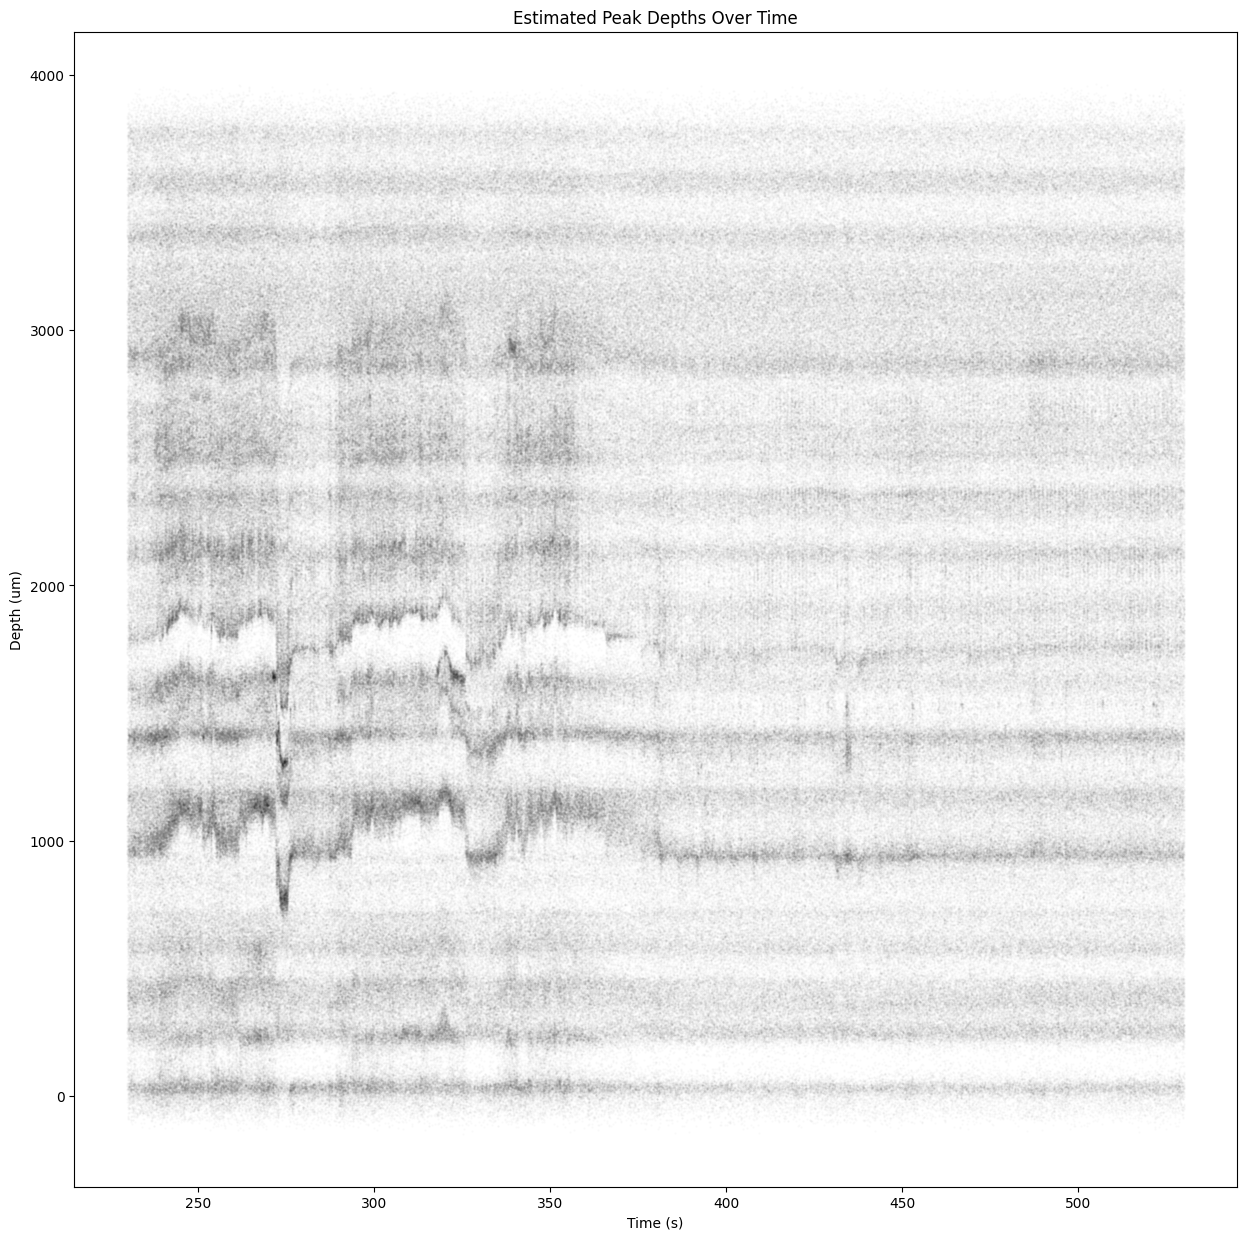

In [ ]:
plot_drift_scatter(peaks, depths, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_raw_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


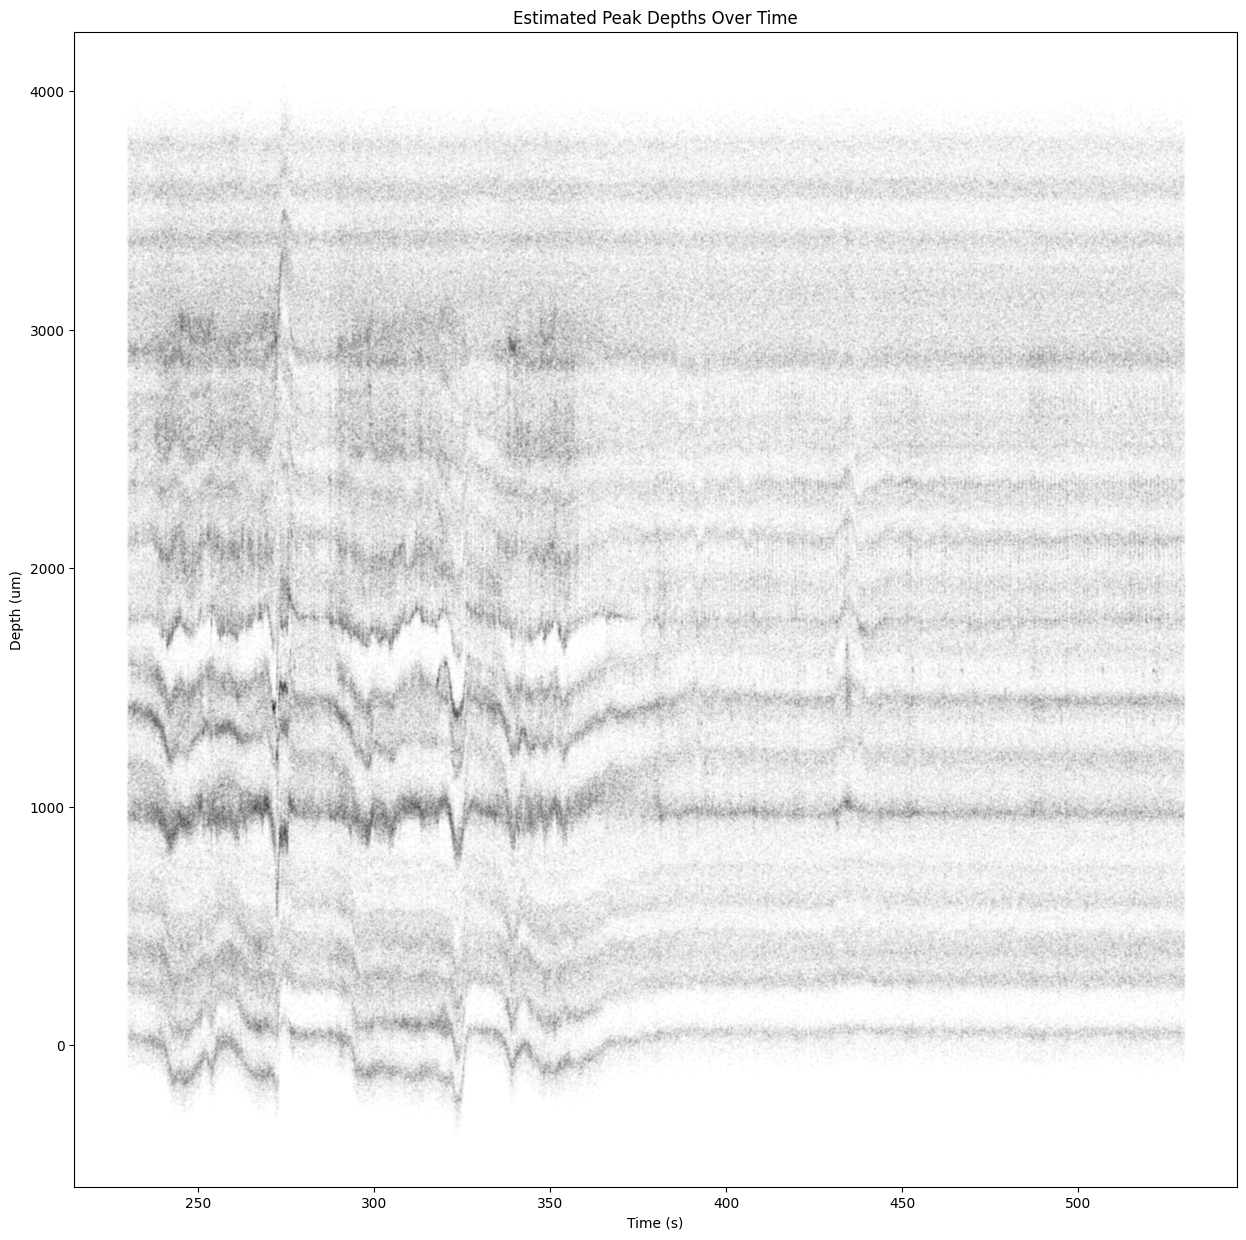

In [ ]:
plot_drift_scatter(peaks, corrected_depths, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_dredge_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


#### **CHANNELS**

In [ ]:
channel_positions = rec.get_channel_locations()   # (n_channels, 2)  col 0=x, col 1=y
channel_depths    = channel_positions[:, 1]        # y-coords in µm

depths2 = channel_depths[peaks["channel_index"]]     # depth of each peak's max channel

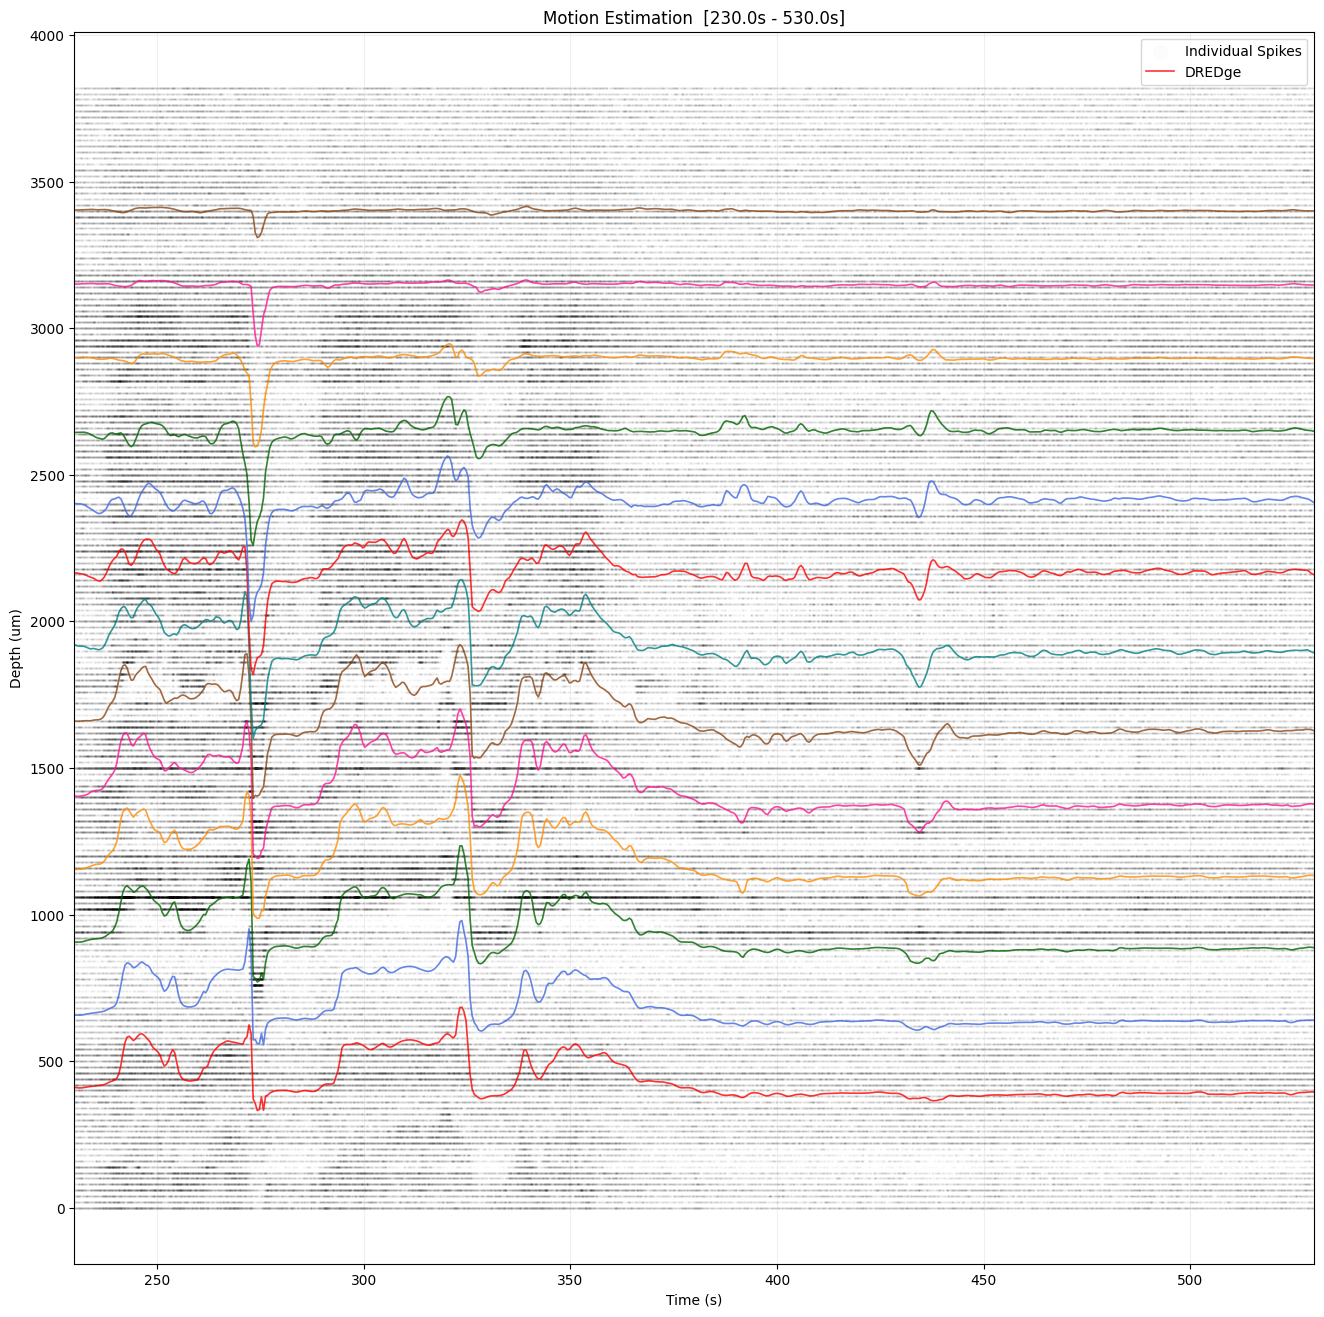

In [ ]:
plot_motion_overlay(
    peaks,
    depths2,
    motion_list=[motion],
    labels=['DREDge'],
    colors=['red'],
    sampling_frequency=rec.sampling_frequency,
    time_offset=time_offset,
    start_time=plot_start_time,
    end_time=plot_end_time,
    save_name=motion_path / f'motion_overlay_dredge_channels_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png'
)


In [ ]:
corrected_depths2 = get_corrected_depths(
    peaks,
    depths2,
    motion,
    rec.sampling_frequency,
    time_offset=time_offset
)

In [ ]:
sort_idx      = np.argsort(channel_depths)
sorted_depths = channel_depths[sort_idx]

ins  = np.searchsorted(sorted_depths, corrected_depths2)
ins  = np.clip(ins, 0, len(sorted_depths) - 1)
left = np.clip(ins - 1, 0, len(sorted_depths) - 1)
closer_left     = np.abs(corrected_depths2 - sorted_depths[left]) < np.abs(corrected_depths2 - sorted_depths[ins])
best_sorted_idx = np.where(closer_left, left, ins)

corrected_channel2        = sort_idx[best_sorted_idx]
corrected_depths2_snapped = channel_depths[corrected_channel2]

changed = corrected_channel2 != peaks['channel_index']
print(f'Peaks reassigned: {changed.sum():,} / {len(peaks):,}  ({100*changed.mean():.1f}%)')


Peaks reassigned: 92,994,409 / 126,258,007  (73.7%)


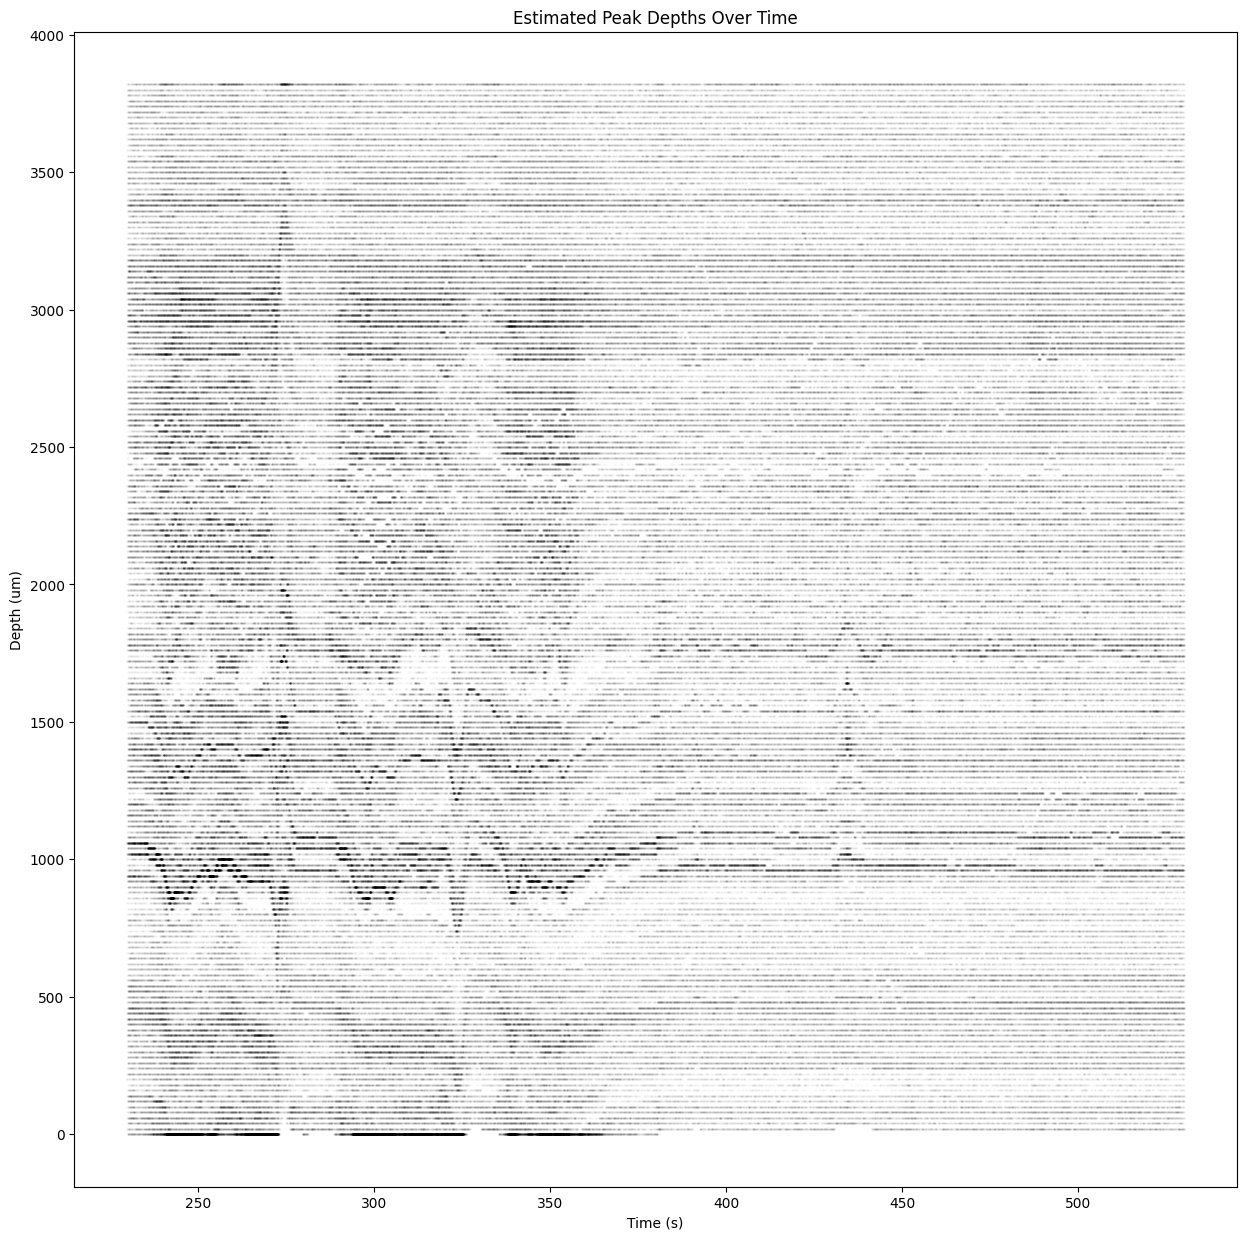

In [ ]:
plot_drift_scatter(peaks, corrected_depths2_snapped, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_dredge_channels_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


In [ ]:
# Binned channel correction: all spikes in each 10s window get the same integer
# channel shift, avoiding the per-spike boundary-flipping problem.
corrected_channel_binned, bin_shifts, bin_centers = get_channel_corrected_binned(
    peaks, channel_depths, motion, rec.sampling_frequency,
    time_offset=time_offset, bin_duration=10
)

changed_binned = corrected_channel_binned != peaks['channel_index']
ch_spacing = float(np.median(np.diff(np.sort(channel_depths))))
print(f'Channel spacing:          {ch_spacing:.1f} um')
print(f'Max integer shift:        {np.abs(bin_shifts).max()} channels')
print(f'Peaks reassigned (binned): {changed_binned.sum():,} / {len(peaks):,}  ({100*changed_binned.mean():.1f}%)')


Channel spacing:          20.0 um
Max integer shift:        13 channels
Peaks reassigned (binned): 60,170,697 / 126,258,007  (47.7%)


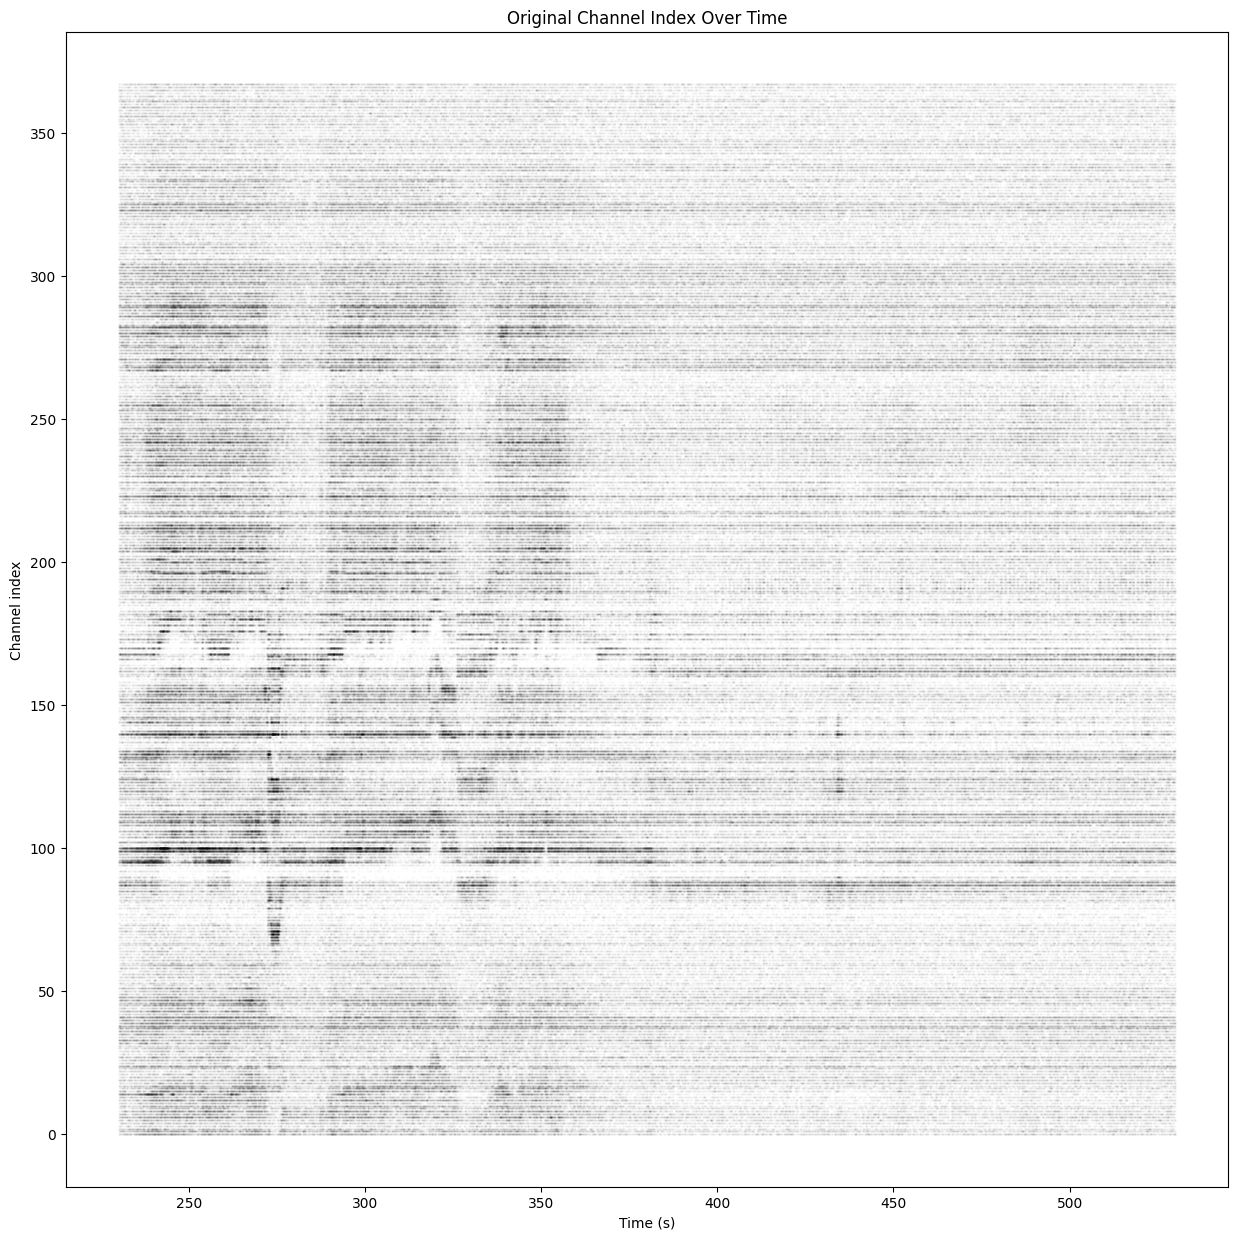

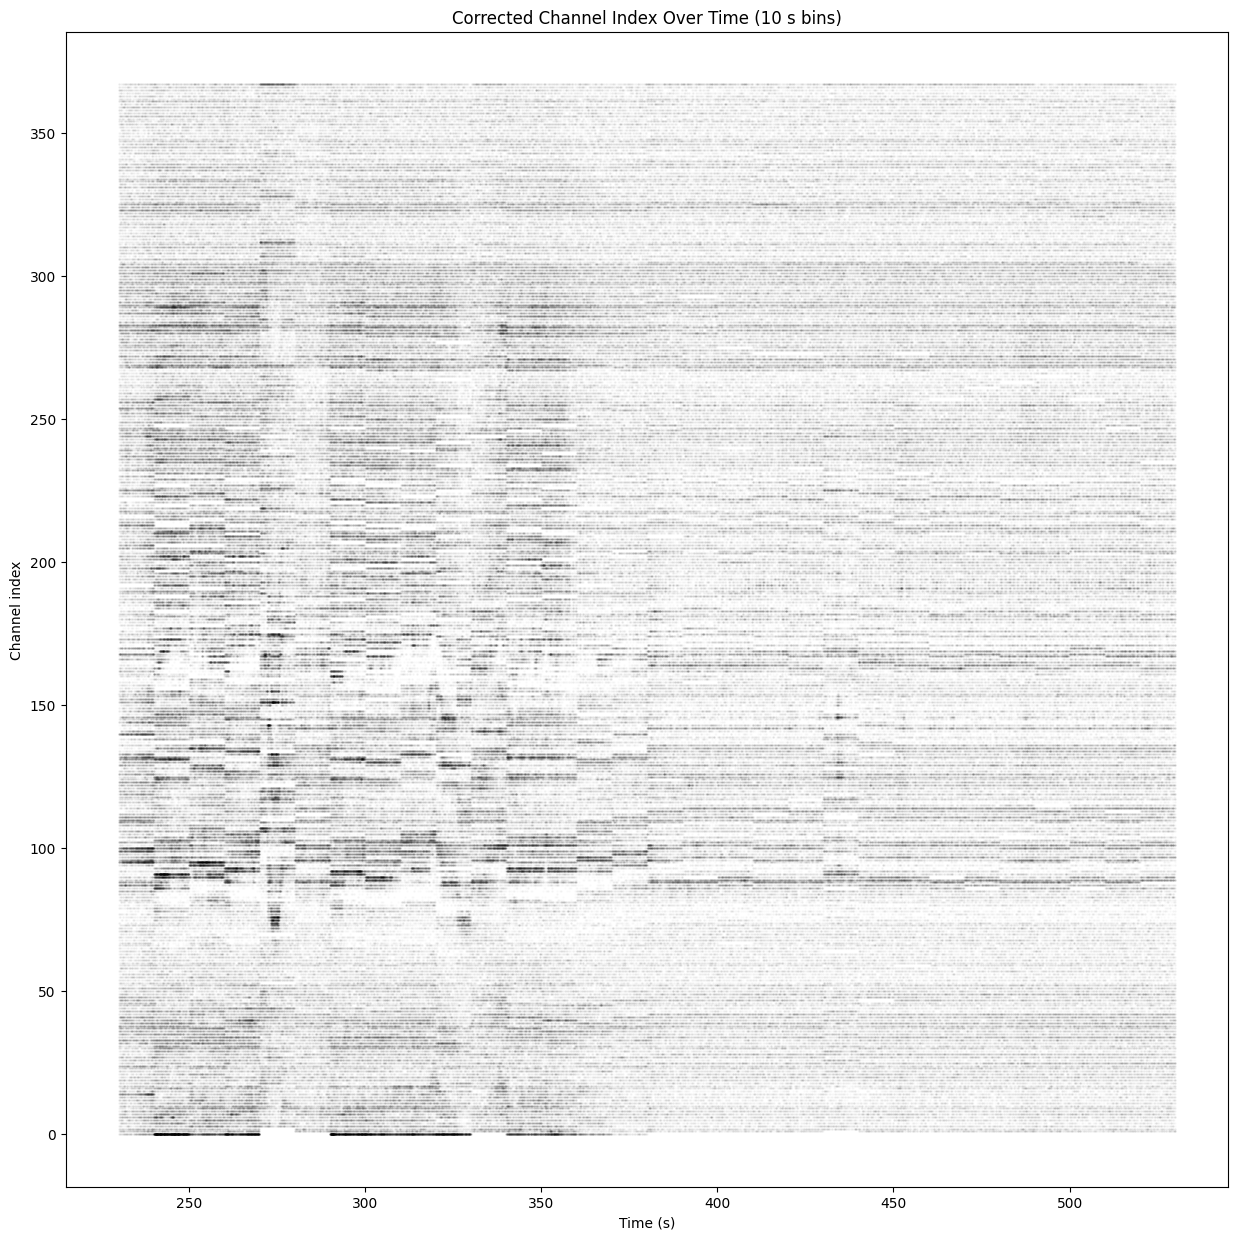

In [ ]:
# --- channel index scatter: shows discrete assignments directly ---
plot_channel_scatter(peaks, peaks['channel_index'], rec.sampling_frequency,
                     t_min=plot_start_time, t_max=plot_end_time,
                     save_name=motion_path / f'channel_scatter_raw_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png',
                     title='Original Channel Index Over Time')

plot_channel_scatter(peaks, corrected_channel_binned, rec.sampling_frequency,
                     t_min=plot_start_time, t_max=plot_end_time,
                     save_name=motion_path / f'channel_scatter_binned_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png',
                     title='Corrected Channel Index Over Time (10 s bins)')


In [ ]:
# # Export for neural decoding
# out_dir = base_dir
# spike_times    = peaks["sample_index"].astype(np.int64)
# spike_clusters = corrected_channel.astype(np.int32)   # cluster id = motion-corrected channel

# np.save(out_dir / "spike_times.npy",    spike_times)
# np.save(out_dir / "spike_clusters.npy", spike_clusters)
# print(f"Saved spike_times ({spike_times.shape}) and spike_clusters ({spike_clusters.shape})")
# print(f"Unique clusters (channels): {np.unique(spike_clusters).size}")


#### **KS4 CORRECTION**

In [ ]:
# kilosort_output_dir = r'/ptmp/gongt/GLC7189/GLC7189_g_g1/KS4/nb5_nc32_n_t9_pcs10_car0_clr1_jobs36_thrd8_te360/sorter_output'
# ops = np.load(os.path.join(kilosort_output_dir, 'ops.npy'), allow_pickle=True).item()
# dshift = ops['dshift']                        # (n_batches, n_depth_bins)  shift in um
# depth_bins_ks4 = ops['yblk']                  # (n_depth_bins,) depth in um
# time_bins_ks4 = (np.arange(ops['Nbatches']) + 0.5) * ops['batch_size'] / ops['fs']  # batch centre times in s
# print(f"dshift shape: {dshift.shape}")
# print(f"time_bins range: {time_bins_ks4.min():.1f} – {time_bins_ks4.max():.1f} s")
# print(f"depth_bins range: {depth_bins_ks4.min():.1f} – {depth_bins_ks4.max():.1f} um")

In [ ]:
# plot_motion_overlay(
#     peaks,
#     depths,
#     motion_list=[{"time_bins": time_bins_ks4, "depth_bins": depth_bins_ks4, "dshift": -dshift}],
#     labels=['KS4'],
#     colors=['red'],
#     sampling_frequency=rec.sampling_frequency,
#     start_time=0*60,
#     end_time=0*60 + 15*60,
#     save_name=motion_path / 'motion_overlay_ks4.png'
# )


In [ ]:
# ks4_corrected_depths = get_corrected_depths(
#     peaks,
#     depths,
#     {"time_bins": time_bins_ks4, "depth_bins": depth_bins_ks4, "dshift": -dshift},
#     rec.sampling_frequency
# )

In [ ]:
# plot_drift_scatter(peaks, ks4_corrected_depths, rec.sampling_frequency, t_min=0*60, t_max=15*60,
#                    save_name=motion_path / 'drift_scatter_ks4_corrected.png')
